In [16]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [17]:
#define state 
class BMIState(TypedDict):
    weight_kg: float
    height_m: float
    bmi: float
    category: str

In [18]:
def calc_bmi(state: BMIState) -> BMIState:
    weight = state['weight_kg']
    height = state['height_m']
    bmi = weight/(height**2)
    state['bmi'] = round(bmi, 2)
    return state

def label_bmi(state: BMIState) -> BMIState:
    bmi = state['bmi']
    if bmi < 18.5:
        state['category'] = "Underweight"
    elif bmi < 25:
        state['category'] = "Normal"
    elif bmi <30:
        state['category'] = "Overweight"
    else:
        state['category'] = "Obese"
    return state

In [20]:
#define graph
graph = StateGraph(BMIState)

#add nodes
graph.add_node('calc_bmi', calc_bmi)
graph.add_node('label_bmi', label_bmi)

#add edges
graph.add_edge(START, 'calc_bmi')
graph.add_edge('calc_bmi', 'label_bmi')
graph.add_edge('label_bmi', END)

#compile the graph
workflow = graph.compile()

In [22]:
#execute the graph
initial_state = {'weight_kg': 60, 'height_m': 1.6}
final_state = workflow.invoke(initial_state)
print(final_state)

{'weight_kg': 60, 'height_m': 1.6, 'bmi': 23.44, 'category': 'Normal'}


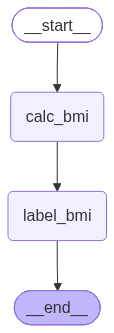

In [21]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())